# Lab 2: Linear Regression (NumPy and PyTorch) and Maximum Likelihood

Deep Learning, Semester 5, Plaksha University.

1. Simple linear regression with the analytical normal-equation solution in NumPy.
2. A PyTorch mini tutorial: tensors, autograd and a built-in linear model.
3. Building and training a linear regression model in PyTorch with MSE loss and SGD.
4. Maximum likelihood estimation for a normal distribution and for coin flips.

## 1. Simple linear regression with NumPy (analytical solution)

The best-fit weights are given by the normal equation $w = (X^T X)^{-1} X^T y$, where $X$ has a column of ones for the intercept.

Calculated intercept (w0): 4.9928   (true value 5)
Calculated slope (w1): 1.9693       (true value 2)
Predicted value for x=10: 24.6855


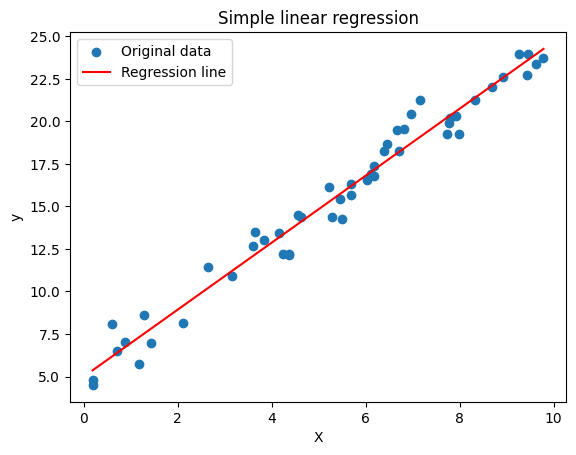

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
X = np.random.rand(50, 1) * 10
y = 2 * X + 5 + np.random.randn(50, 1)

X_b = np.c_[np.ones((50, 1)), X]                      # add bias column
w_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y         # normal equation
w_0, w_1 = w_best[0, 0], w_best[1, 0]
print(f"Calculated intercept (w0): {w_0:.4f}   (true value 5)")
print(f"Calculated slope (w1): {w_1:.4f}       (true value 2)")


def predict(x, w_0, w_1):
    return w_0 + w_1 * x


print(f"Predicted value for x=10: {predict(10, w_0, w_1):.4f}")

xs = np.sort(X, axis=0)
plt.scatter(X, y, label="Original data")
plt.plot(xs, predict(xs, w_0, w_1), color="red", label="Regression line")
plt.title("Simple linear regression"); plt.xlabel("X"); plt.ylabel("y"); plt.legend()
plt.show()

## 2. PyTorch mini tutorial

Tensors are PyTorch's version of NumPy arrays (they can also run on GPUs) and support automatic differentiation.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(0)
a = torch.tensor([1, 2, 3])
b = torch.tensor([4, 5, 6])
print(a + b)              # element-wise addition
print(a * b)              # element-wise multiplication
print(a @ b)              # dot product: 1*4 + 2*5 + 3*6 = 32
print(a.float().mean())   # mean needs a floating-point tensor

x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3 * x + 1
y.backward()              # autograd computes dy/dx
print("dy/dx at x=2:", x.grad.item(), "(expected 2*2 + 3 = 7)")

tensor([5, 7, 9])
tensor([ 4, 10, 18])
tensor(32)
tensor(2.)
dy/dx at x=2: 7.0 (expected 2*2 + 3 = 7)


In [3]:
# Built-in linear model fitted to y = 2x + 3 with L1 loss and Adam
X_t = torch.randn(100, 1) * 10
y_t = 2 * X_t + 3
model = nn.Linear(1, 1)
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
for epoch in range(1000):
    loss = criterion(model(X_t), y_t)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch + 1}, loss = {loss.item():.4f}")
print("Prediction for x=5:", round(model(torch.tensor([[5.0]])).item(), 4), "(true value 13)")

Epoch 200, loss = 2.2155


Epoch 400, loss = 0.0055


Epoch 600, loss = 0.0109


Epoch 800, loss = 0.0083


Epoch 1000, loss = 0.0051
Prediction for x=5: 12.9948 (true value 13)


## 3. Building my own linear regression model in PyTorch

Synthetic data $y = 4x - 2 + \text{noise}$, a model defined as an `nn.Module`, mean squared error loss and stochastic gradient descent.

Epoch 400: MSE = 1.8152


Epoch 800: MSE = 1.7796


Epoch 1200: MSE = 1.7789


Epoch 1600: MSE = 1.7789


Epoch 2000: MSE = 1.7789

Learned slope = 4.001 (true 4), learned intercept = -1.807 (true -2)
Sample prediction for x = 7: 26.201 (true mean 26)


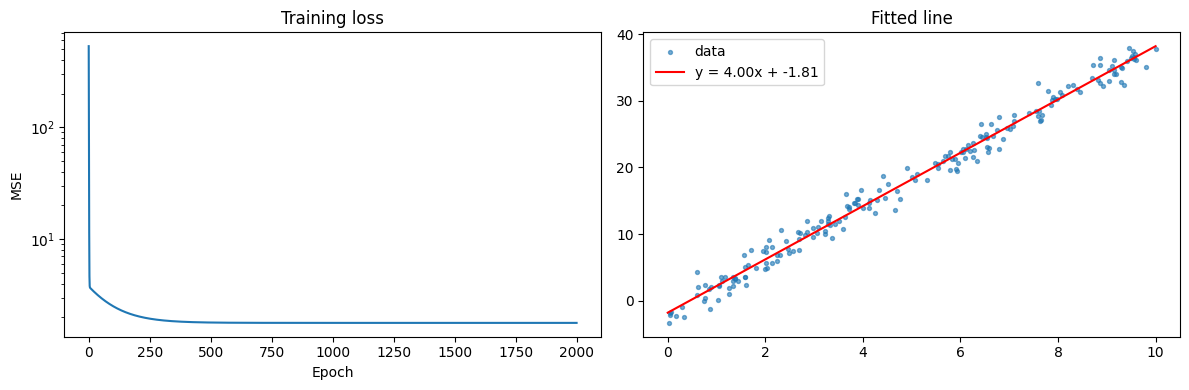

In [4]:
torch.manual_seed(42)
X_train = torch.rand(200, 1) * 10
y_train = 4 * X_train - 2 + torch.randn(200, 1) * 1.5    # true slope 4, intercept -2


class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


my_model = LinearRegressionModel()
criterion = nn.MSELoss()
optimizer = optim.SGD(my_model.parameters(), lr=0.01)

losses = []
for epoch in range(2000):
    loss = criterion(my_model(X_train), y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 400 == 0:
        print(f"Epoch {epoch + 1}: MSE = {loss.item():.4f}")

w, b = my_model.linear.weight.item(), my_model.linear.bias.item()
print(f"\nLearned slope = {w:.3f} (true 4), learned intercept = {b:.3f} (true -2)")
print(f"Sample prediction for x = 7: {my_model(torch.tensor([[7.0]])).item():.3f} (true mean 26)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses); axes[0].set_yscale("log"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE"); axes[0].set_title("Training loss")
axes[1].scatter(X_train, y_train, s=8, alpha=0.6, label="data")
xs = torch.linspace(0, 10, 50).unsqueeze(1)
axes[1].plot(xs, my_model(xs).detach(), "r", label=f"y = {w:.2f}x + {b:.2f}")
axes[1].legend(); axes[1].set_title("Fitted line")
plt.tight_layout()
plt.savefig("images/lab02_pytorch_regression.png")
plt.show()

## 4. Maximum likelihood estimation

For data $x_1, \dots, x_n$ from a normal distribution, the log-likelihood is

$$\log L(\mu, \sigma) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_i (x_i - \mu)^2$$

The maximum likelihood estimates are the sample mean and the (biased, divide-by-$n$) sample standard deviation. For coin flips, the MLE of $P(\text{heads})$ is the fraction of heads.

Log-likelihood at mu=4.5, sigma=1.0: -5.8647
mu that maximises the likelihood: 4.615  (sample mean 4.620)


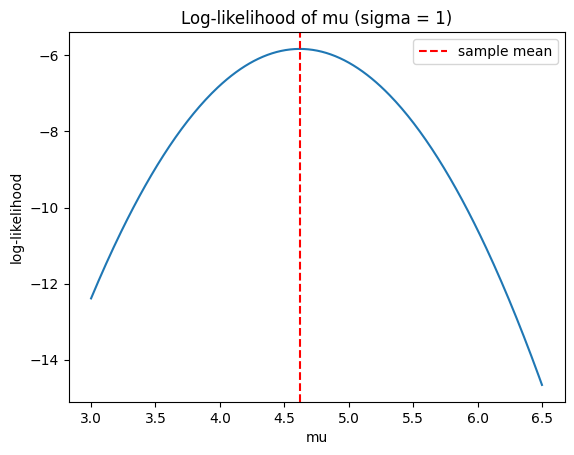

In [5]:
def log_likelihood(mu, sigma, data):
    n = len(data)
    sigma_sq = sigma**2 + 1e-9
    log_L = -n / 2 * np.log(2 * np.pi * sigma_sq) - np.sum((data - mu) ** 2) / (2 * sigma_sq)
    return log_L


data = np.array([3.5, 4.2, 5.1, 4.8, 5.5])
print(f"Log-likelihood at mu=4.5, sigma=1.0: {log_likelihood(4.5, 1.0, data):.4f}")

mus = np.linspace(3, 6.5, 300)
lls = [log_likelihood(m, 1.0, data) for m in mus]
print(f"mu that maximises the likelihood: {mus[np.argmax(lls)]:.3f}  (sample mean {data.mean():.3f})")
plt.plot(mus, lls); plt.axvline(data.mean(), color="r", ls="--", label="sample mean")
plt.xlabel("mu"); plt.ylabel("log-likelihood"); plt.title("Log-likelihood of mu (sigma = 1)"); plt.legend()
plt.show()

In [6]:
data = np.array([8.5, 9.2, 10.1, 3.8, 15.5])
sample_mean = np.mean(data)
sample_std = np.std(data)            # divide by n: the maximum likelihood estimate
print(f"Sample mean: {sample_mean:.4f}")
print(f"Sample standard deviation (MLE, divide by n): {sample_std:.4f}")
print(f"Unbiased sample standard deviation (divide by n-1): {np.std(data, ddof=1):.4f}")

coin_flips = np.array([1, 0, 1, 1, 0, 1, 0, 1, 1, 1])
mle_p = coin_flips.mean()            # number of heads / number of flips
print(f"MLE for the probability of heads (p): {mle_p:.2f}")

Sample mean: 9.4200
Sample standard deviation (MLE, divide by n): 3.7392
Unbiased sample standard deviation (divide by n-1): 4.1806
MLE for the probability of heads (p): 0.70
